In [25]:
np.logspace(-1, np.log10(10), 400)

array([ 0.1       ,  0.10116086,  0.1023352 ,  0.10352318,  0.10472494,
        0.10594066,  0.10717048,  0.10841459,  0.10967313,  0.11094629,
        0.11223423,  0.11353711,  0.11485512,  0.11618844,  0.11753723,
        0.11890167,  0.12028196,  0.12167827,  0.12309079,  0.12451971,
        0.12596521,  0.1274275 ,  0.12890676,  0.13040319,  0.131917  ,
        0.13344837,  0.13499753,  0.13656467,  0.13815   ,  0.13975373,
        0.14137608,  0.14301727,  0.1446775 ,  0.14635701,  0.14805602,
        0.14977475,  0.15151343,  0.15327229,  0.15505158,  0.15685152,
        0.15867235,  0.16051432,  0.16237767,  0.16426266,  0.16616953,
        0.16809853,  0.17004992,  0.17202397,  0.17402094,  0.17604108,
        0.17808468,  0.180152  ,  0.18224332,  0.18435892,  0.18649908,
        0.18866408,  0.19085421,  0.19306977,  0.19531105,  0.19757835,
        0.19987196,  0.20219221,  0.20453938,  0.20691381,  0.2093158 ,
        0.21174567,  0.21420375,  0.21669036,  0.21920585,  0.22

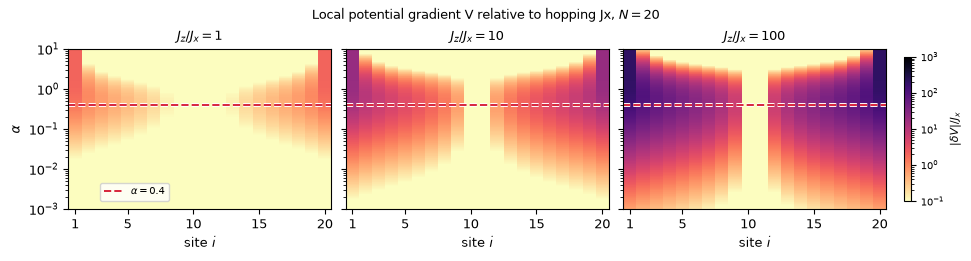

In [54]:
"""
Confinement map: degree of Wannier-Stark freezing of each site, vs alpha.

Single excitation (b = 1), open chain, sites 1..N.
Tilt across bond (i, i+1):   |dV(i)| = 2 Jz | i^-a - (N-i)^-a |

A site's escape route is its centerward bond (the edgeward bond is always
steeper). Each site is colored by |dV|/Jx across that bond: the larger the
tilt relative to the hopping, the more strongly the site is confined.
|dV|/Jx << 1: free hopping;  |dV|/Jx >> 1: Wannier-Stark frozen.
No threshold is imposed; the crossover is at |dV|/Jx ~ O(1).
"""
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

# ---------------- parameters ----------------
N = 20
Jx = 1.0
Jz_list = [1, 10, 100]                  # one panel per Jz
alphas = np.logspace(-3, 1, 400)          # log-spaced, 1e-3 .. 10 (alpha = 0 is flat)
alpha_mark = 0.4                        # red dashed reference line
VMIN, VMAX = 1e-1, 1e3                  # color range of |dV|/Jx (log scale)
C_LINE = "#d7263d"
# magma, reversed: bright = mobile (small tilt), dark = confined (large tilt)
cmap = plt.get_cmap("magma_r")
# --------------------------------------------


def confinement(N, a, Jz, Jx=1.0):
    """|dV|/Jx across each site's centerward bond, for sites 1..N."""
    s = np.arange(1, N + 1, dtype=float)
    # bond index of each site's centerward bond (mirror on the right half)
    i = np.where(s <= N / 2, s, N - s + 1)
    tilt = 2 * Jz * np.abs(i ** (-a) - (N - i) ** (-a))    # |dV| of that bond
    return tilt / Jx


fig, axes = plt.subplots(1, len(Jz_list), figsize=(3 * len(Jz_list) + 0.6, 2.5),
                         sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)

# cell edges for pcolormesh (geometric midpoints), clipped to [alpha_min, alpha_max]
a_edges = np.concatenate([[alphas[0]], np.sqrt(alphas[:-1] * alphas[1:]), [alphas[-1]]])
s_edges = np.arange(0.5, N + 1.5)

for ax, Jz in zip(axes, Jz_list):
    C = np.array([confinement(N, a, Jz, Jx) for a in alphas])     # (alpha, site)
    C = np.clip(C, VMIN, VMAX)                                   # center: dV = 0 -> floor
    im = ax.pcolormesh(s_edges, a_edges, C, cmap=cmap, norm=LogNorm(VMIN, VMAX),
                       shading="flat", rasterized=True)
    ax.axhline(alpha_mark, color=C_LINE, lw=1.4, ls="--",
               path_effects=[pe.Stroke(linewidth=2.8, foreground="white"), pe.Normal()])
    ax.set_yscale("log")
    ax.set_ylim(alphas[0], alphas[-1])
    ax.set_xlabel(r"site $i$")
    ax.set_xlim(0.5, N + 0.5)
    ax.set_xticks([1, N // 4, N // 2, 3 * N // 4, N])
    ax.set_title(fr"$J_z/J_x={Jz/Jx:g}$", fontsize=9)

axes[0].set_ylabel(r"$\alpha$")
cb = fig.colorbar(im, ax=axes, shrink=0.9, pad=0.02)
cb.set_label(r"$|\delta V|/J_x$", fontsize=8)
cb.ax.tick_params(labelsize=7)
axes[0].legend(handles=[Line2D([], [], color=C_LINE, lw=1.4, ls="--",
                                label=fr"$\alpha={alpha_mark:g}$")],
                fontsize=7, frameon=True, framealpha=0.8,
                loc="lower right", bbox_to_anchor=(0.4, 0.02))
fig.suptitle(fr"Local potential gradient V relative to hopping Jx, $N={N}$", fontsize=9)

os.makedirs("plt", exist_ok=True)
fig.savefig("plt/confinement_map.pdf")
# fig.savefig("confinement_map.png", dpi=200)

array([  1.        ,   1.27427499,   1.62377674,   2.06913808,
         2.6366509 ,   3.35981829,   4.2813324 ,   5.45559478,
         6.95192796,   8.8586679 ,  11.28837892,  14.38449888,
        18.32980711,  23.35721469,  29.76351442,  37.92690191,
        48.32930239,  61.58482111,  78.47599704, 100.        ])

In [ ]:
import os
import numpy as np
import pandas as pd

# ============================================================
# Single-particle Hamiltonian (b = 1 sector)
# ============================================================

def build_H_b1(N, Jx, Jz, alpha):
    """Builds the single-particle sector Hamiltonian with power-law confinement."""
    H = np.zeros((N, N), dtype=np.float64)

    # 1. Diagonal confinement potential
    for k in range(N):
        V = 0.0
        for j in range(N):
            if j != k:
                V += 1.0 / (abs(k - j) ** alpha)
        H[k, k] = -2.0 * Jz * V

    # 2. Nearest-neighbor hopping
    for k in range(N - 1):
        H[k, k + 1] = Jx
        H[k + 1, k] = Jx

    return H

# ============================================================
# Computation & Overlaps
# ============================================================

def compute_site_metrics(H, k):
    """
    Computes the IPR and local potential differences at site k.
    Note: np.linalg.eigh returns eigenvectors as COLUMNS (evecs[:, n]).
    """
    evals, evecs = np.linalg.eigh(H)
    
    # Overlap array: <k|n> for all eigenstates n
    overlaps = evecs[k, :]  # Components of all eigenvectors at site k
    
    ipr = np.sum(np.abs(overlaps) ** 4)
    
    # Extract the local potential gradient Delta_k = V(k) - V(k+1)
    # Using the diagonal elements of H directly
    V_k = H[k, k]
    V_neighbor = H[k + 1, k + 1] if k < len(H) - 1 else H[k - 1, k - 1]
    delta_k = abs(V_k - V_neighbor)
    
    return float(ipr), delta_k

# ============================================================
# Parameters & Initialization
# ============================================================

N = 100
Jx = 1
alpha = 0.2
k = 0  # Target site for observation

Jz_vals = np.logspace(0, 2, 30)

IPR = np.zeros(len(Jz_vals))
P_leak = np.zeros(len(Jz_vals))
P_leak_theory = np.zeros(len(Jz_vals))

print(f"Running sweep for site k = {k} in system size N = {N}...\n")
print(f"{'Idx':>4} | {'Jz':>10} | {'IPR':>12} | {'P_leak (Num)':>12} | {'P_leak (Theory)':>12}")
print("-" * 65)

# ============================================================
# Sweep over Jx
# ============================================================

for idx, Jz in enumerate(Jz_vals):
    H = build_H_b1(N=N, Jx=Jx, Jz=Jz, alpha=alpha)
    
    ipr, delta_k = compute_site_metrics(H, k)
    
    IPR[idx] = ipr
    P_leak[idx] = 1.0 - ipr
    
    # First-order perturbation theory prediction: P_leak ~ 2 * (Jx / Delta_k)^2
    P_leak_theory[idx] = 2.0 * (Jx / delta_k) ** 2

    print(
        f"{idx+1:4d} | "
        f"{Jz:.3e} | "
        f"{ipr:.8f} | "
        f"{P_leak[idx]:.4e} | "
        f"{P_leak_theory[idx]:.4e}"
    )

# ============================================================
# Save Data
# ============================================================

output_dir = "ED_Data/SpatialConfinement"
os.makedirs(output_dir, exist_ok=True)

df = pd.DataFrame({
    "Jz": Jz_vals,
    "IPR": IPR,
    "P_leak_numerical": P_leak,
    "P_leak_theoretical": P_leak_theory
})

filename = os.path.join(output_dir, "IPR_vs_Jz.csv")
df.to_csv(filename, index=False)

print("\n" + "=" * 65)
print(f"Data successfully saved to: {filename}")

Running sweep for site k = 0 in system size N = 100...

 Idx |         Jz |          IPR | P_leak (Num) | P_leak (Theory)
-----------------------------------------------------------------
   1 | 1.000e+00 | 0.49072281 | 5.0928e-01 | 1.3838e+00
   2 | 1.172e+00 | 0.55549436 | 4.4451e-01 | 1.0073e+00
   3 | 1.374e+00 | 0.62017935 | 3.7982e-01 | 7.3321e-01
   4 | 1.610e+00 | 0.68261319 | 3.1739e-01 | 5.3370e-01
   5 | 1.887e+00 | 0.74065803 | 2.5934e-01 | 3.8848e-01
   6 | 2.212e+00 | 0.79255495 | 2.0745e-01 | 2.8277e-01
   7 | 2.593e+00 | 0.83722443 | 1.6278e-01 | 2.0583e-01
   8 | 3.039e+00 | 0.87436688 | 1.2563e-01 | 1.4982e-01
   9 | 3.562e+00 | 0.90434745 | 9.5653e-02 | 1.0905e-01
  10 | 4.175e+00 | 0.92796396 | 7.2036e-02 | 7.9380e-02
  11 | 4.894e+00 | 0.94620996 | 5.3790e-02 | 5.7780e-02
  12 | 5.736e+00 | 0.96009604 | 3.9904e-02 | 4.2058e-02
  13 | 6.723e+00 | 0.97054333 | 2.9457e-02 | 3.0614e-02
  14 | 7.880e+00 | 0.97833570 | 2.1664e-02 | 2.2284e-02
  15 | 9.237e+00 | 0.9841104

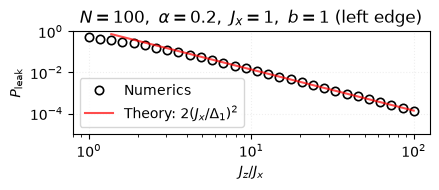

Fitted exponent: -0.2755 (expected: -2)


In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- parameters (must match the sweep script; better: store them in the CSV) ----
N, Jx, alpha = 100, 1.0, 0.2

df = pd.read_csv("ED_Data/SpatialConfinement/IPR_vs_Jz.csv")
Jz  = df["Jz"].to_numpy()
num = df["P_leak_numerical"].to_numpy()
th  = df["P_leak_theoretical"].to_numpy()

# ---- fit in the perturbative regime: large Jz ----
fit_mask = Jz >= 10
slope, intercept = np.polyfit(np.log10(Jz[fit_mask]), np.log10(num[fit_mask]), 1)

# ---- plot ----
fig, ax = plt.subplots(figsize=(4.5, 2))
ax.loglog(Jz, num, "o", mfc="white", mec="black", mew=1.2, label="Numerics")

th_mask = th < 1                      # show PT only where it is valid
ax.loglog(Jz[th_mask], th[th_mask], "-", color="red", alpha=0.7,
          label=r"Theory: $2(J_x/\Delta_1)^2$")

# ax.loglog(Jz[fit_mask], 10**(slope*np.log10(Jz[fit_mask]) + intercept), "--",
#           color="grey", label=rf"fit: slope $\approx {slope:.2f}$")

ax.set_xlabel(r"$J_z/J_x$")
ax.set_ylabel(r"$P_{\rm leak}$")
ax.set_title(rf"$N={N},\ \alpha={alpha},\ J_x={1},\ b=1$ (left edge)")
ax.set_ylim(1e-5, 1)
ax.grid(True, which="major", alpha=0.2, linestyle=":")
ax.legend(loc="lower left", frameon=True)
fig.tight_layout()

os.makedirs("Plt", exist_ok=True)
fig.savefig("Plt/Pleak_scaling_Jz.pdf")
plt.show()

print(f"Fitted exponent: {(slope+2)/slope*100:.4f} (expected: -2)")

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# INITIAL CONFIGURATION
# ============================================================
N = 100
Jz = 10.0
# Bx = 1.0
alpha = 0.2
# tmax = 100

# Even integer couplings used in your updated simulation script
Jz_list = np.arange(2, 22, 2)

output_dir = "ED_Data/SectorConfinement"
avg_leakage = []

# Choose your time-averaging window exactly (thanks to your arange time setup)
t_start = 0.0

# ============================================================
# LOAD INDIVIDUAL FILES AND COMPUTE LEAKAGE
# ============================================================
for Jx in Jz_list:
    Jz_int = int(Jz)

    # Try matching the float format first (e.g., Jz2.00)
    filename = f"Pleak_N{N}_Jz{Jz_int:.2f}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
    full_path = os.path.join(output_dir, filename)

    # Fallback to pure integer format (e.g., Jz2) if the float one doesn't exist
    if not os.path.exists(full_path):
        filename_alt = f"Pleak_N{N}_Jz{Jz_int}_Jx{Jx:.1f}_Bx{Bx:.1f}_alpha{alpha}_tmax{tmax}.csv"
        full_path = os.path.join(output_dir, filename_alt)

    # If neither format exists, raise the clear error
    if not os.path.exists(full_path):
        raise FileNotFoundError(
            f"Could not find saved data file at:\n  {full_path}\n"
            f"Please verify the files in '{output_dir}' match this parameter configuration."
        )

    # Load raw time data
    df = pd.read_csv(full_path)
    t_arr = df["time"].to_numpy()
    P_t = df["Pstay"].to_numpy()

    # Slice out the transient-free window dynamically
    time_mask = t_arr >= t_start
    P_stay_avg = np.mean(P_t[time_mask])

    # Leakage = 1 - P_stay
    avg_leakage.append(1 - P_stay_avg)

# ============================================================
# POWER LAW FITTING
# ============================================================
# Convert to log-space for fitting
log_Jz = np.log10(Jz_list)
log_leak = np.log10(avg_leakage)

# Fit a line (y = mx + c)
slope, intercept = np.polyfit(log_Jz, log_leak, 1)
fit_line = 10 ** (slope * log_Jz + intercept)

# ============================================================
# PLOT WITH FIT
# ============================================================
plt.figure(figsize=(4.5, 2))
plt.plot(Jz_list, avg_leakage, "o", mfc="white", label="Data")
plt.plot(
    Jz_list, fit_line, "--", color="red", label=fr"Fit: power $\approx {slope:.0f}$"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Coupling $J_z$")
plt.ylabel(fr"$\langle P_{{leak}} \rangle_{{t \in [{int(t_start)},{tmax}]}}$")
plt.title(
    fr"band 1 (N={N}, $\alpha$={alpha}, Jx={Jx:.1f}, Bx={Bx:.1f})"
)
plt.grid(True, which="major", alpha=0.3)
plt.legend(loc="lower left", frameon=False)
plt.tight_layout()

# Save figure
os.makedirs("plt", exist_ok=True)
plt.savefig("plt/Pleak_Jz.pdf")
plt.show()

print(f"Calculated Power Law Exponent: {slope:.4f}")

ModuleNotFoundError: No module named 'matplotlib.backends.registry'